<a href="https://colab.research.google.com/github/jegillis323/MAT-422/blob/main/MAT422_Section_3_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT 422 - Section 3.4: Logistic Regression

**Topics:** Sigmoid/logistic function, Binary classification probabilities, Logistic regression fitting and interpretation

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

#3.4.1 Sigmoid/Logic Function

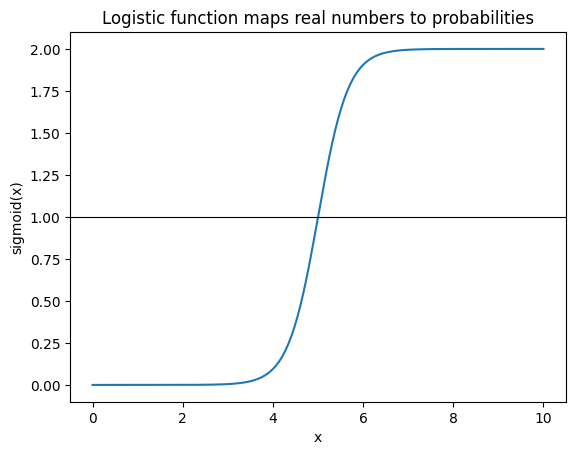

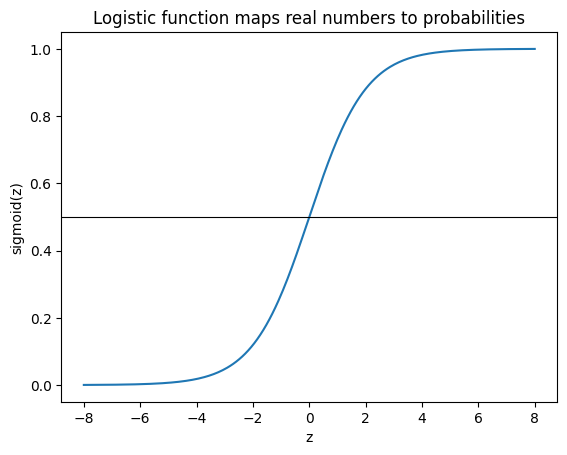

In [18]:
def sigmoid(L, k, x, x_0):
    return L/(1 + np.exp(-k*(x-x_0)))

def standard_sigmoid(z):
    return 1 / (1 + np.exp(-z))

L = 2
k = 3
x = np.linspace(0, 10, 300)
x_0 = 5
plt.plot(x, sigmoid(L, k, x, x_0))
plt.axhline(1, color="black", linewidth=0.8)
plt.xlabel("x")
plt.ylabel("sigmoid(x)")
plt.title("Logistic function maps real numbers to probabilities")
plt.show()

z = np.linspace(-8, 8, 300)
plt.plot(z, standard_sigmoid(z))
plt.axhline(0.5, color="black", linewidth=0.8)
plt.xlabel("z")
plt.ylabel("sigmoid(z)")
plt.title("Logistic function maps real numbers to probabilities")
plt.show()

My Explanation: The logistic function is a function that converts any number into a range from 0 to 1, where if $z\ll0\rightarrow sigmoid(z)\approx0$, $z=0\rightarrow sigmoid(z)\approx0.5$, and $z\gg0\rightarrow sigmoid(z)\approx1$. The function is $\frac{L}{1+e^{-k(x-x_0)}}$ standard form of the function is $\frac{1}{1+e^{-z}}$ and those can be seen in the two graphs.

#3.4.2 Binary Classification Probabilities

In [19]:
X, y = make_classification(n_samples=150, n_features=2, n_redundant=0, n_informative=2, n_clusters_per_class=1, class_sep=1.0, random_state=323)

model = LogisticRegression()
model.fit(X, y)

probabilities = model.predict_proba(X)[:, 1]

predictions = (probabilities >= 0.5).astype(int)

print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)
print("Training accuracy:", accuracy_score(y, predictions))

print("\nFirst 10 probabilities:")
print(probabilities[:10])

print("\nFirst 10 predicted classes:")
print(predictions[:10])

print("\nFirst 10 actual classes:")
print(y[:10])

print("\nConfusion Matrix:")
print(confusion_matrix(y, predictions))

Coefficients: [[3.86380635 0.81980186]]
Intercept: [-0.3462626]
Training accuracy: 0.9733333333333334

First 10 probabilities:
[0.75779243 0.25101517 0.09666793 0.99926434 0.99888131 0.11845072
 0.77967912 0.084263   0.99013889 0.98507528]

First 10 predicted classes:
[1 0 0 1 1 0 1 0 1 1]

First 10 actual classes:
[1 0 0 1 1 0 1 0 1 1]

Confusion Matrix:
[[74  1]
 [ 3 72]]


My Explanation: The probabilities generates random values of probabilites ranging from 0 to 1. From this, the predictions takes any value $>0.5$ to be 1 and anything $<0.5$ to be 0. The confusion matrix then shows the amount of correctly identified 0s, incorrectly indentified 0s as 1s, incorrectly indentifed 1s as 0s, and correctly identified 1s.

#3.4.3 Logistic Regression Fitting and Interpretation

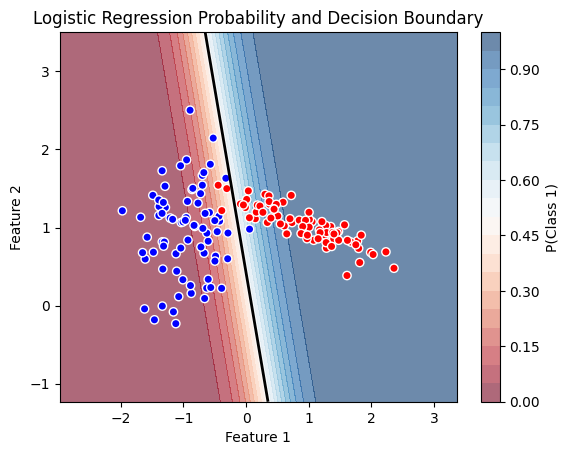

In [20]:
xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 200), np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 200))

grid = np.c_[xx.ravel(), yy.ravel()]
probability_surface = model.predict_proba(grid)[:, 1].reshape(xx.shape)

plt.contourf(xx, yy, probability_surface, levels=20, cmap="RdBu", alpha=0.6)

plt.colorbar(label="P(Class 1)")

plt.contour(xx, yy, probability_surface, levels=[0.5], colors="black", linewidths=2)

plt.scatter(X[:, 0], X[:, 1], c=y, edgecolor="white", cmap="bwr")

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Logistic Regression Probability and Decision Boundary")
plt.show()

My Explanation: The heatmap shows the split of the probability of class 1 the values from the previous part with the boundary line at $0.5$. Most of the dots are correctly aligned with the probability, where to the left of the line is class 0 and to the right of the line is class 1. Points closer to the line are closer to 0.5, which is why a few of them are misclassified as the opposite class.